In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

# Models
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Set plot style for professional looking graphs
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load Data
csv_file = 'heart_synthetic_50000.csv'
df = pd.read_csv(csv_file)

# Prepare X and y
X = df.drop(columns=['target'])
y = df['target']

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("✅ Setup Complete. Data Loaded.")

✅ Setup Complete. Data Loaded.


In [2]:
# Define the dictionary of pipelines (same as your train_model.py)
pipelines = {
    'Logistic Regression': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(random_state=42))]),
    'Support Vector Machine': Pipeline([('scaler', StandardScaler()), ('clf', SVC(probability=True, random_state=42))]),
    'K-Nearest Neighbors': Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=5))]),
    'Decision Tree': Pipeline([('scaler', StandardScaler()), ('clf', DecisionTreeClassifier(random_state=42))]),
    'Naive Bayes': Pipeline([('scaler', StandardScaler()), ('clf', GaussianNB())]),
    'Random Forest': Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(n_estimators=100, random_state=42))])
}

results = []

print("⚙️ Training models... this might take a moment.")

for name, pipe in pipelines.items():
    # Train
    pipe.fit(X_train, y_train)
    
    # Predict
    y_pred = pipe.predict(X_test)
    
    # Calculate Standard Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    # Calculate Specificity (True Negative Rate)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp)
    
    # Store results
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1 Score': f1,
        'Specificity': specificity
    })
    print(f"Finished: {name}")

# Create a DataFrame for easy plotting
results_df = pd.DataFrame(results)
print("\n✅ Training Complete! Here are the results:")
display(results_df)

⚙️ Training models... this might take a moment.
Finished: Logistic Regression
Finished: Support Vector Machine
Finished: K-Nearest Neighbors
Finished: Decision Tree
Finished: Naive Bayes
Finished: Random Forest

✅ Training Complete! Here are the results:


,Model,Accuracy,Precision,Recall,F1 Score,Specificity
0,Logistic Regression,0.8911,0.921244,0.867136,0.893371,0.917704
1,Support Vector Machine,0.9076,0.900018,0.927390,0.913499,0.885630
2,K-Nearest Neighbors,0.9000,0.901451,0.909333,0.905375,0.889639
3,Decision Tree,0.8448,0.852634,0.852309,0.852471,0.836463
4,Naive Bayes,0.8839,0.929229,0.843566,0.884328,0.928677
5,Random Forest,0.9093,0.895100,0.937464,0.915792,0.878033


C:\Users\spars\AppData\Local\Temp\ipykernel_26132\1088922026.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.barplot(x='Model', y='Accuracy', data=results_df, palette='viridis')


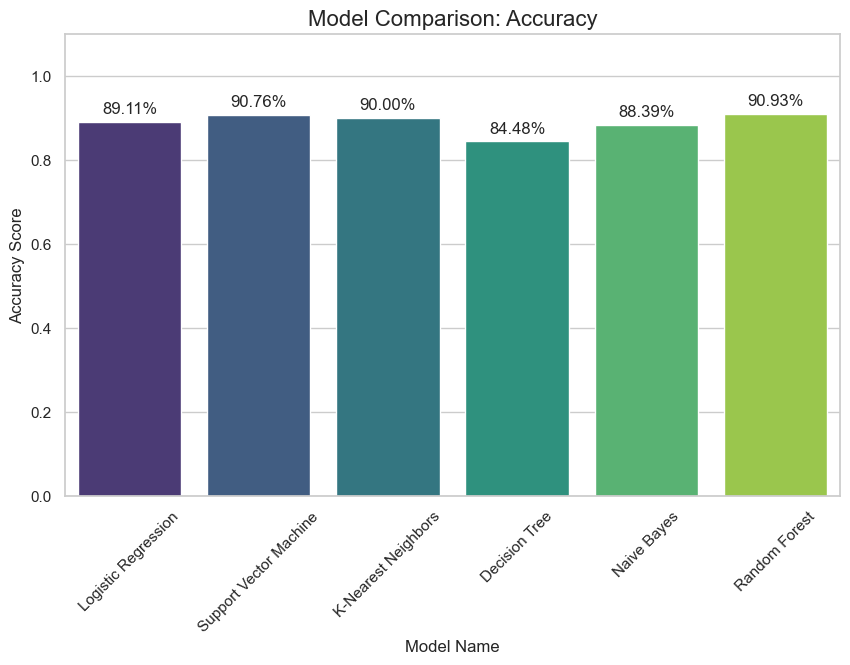

In [3]:
plt.figure(figsize=(10, 6))
# Create bar chart
plot = sns.barplot(x='Model', y='Accuracy', data=results_df, palette='viridis')

# Add labels
plt.title('Model Comparison: Accuracy', fontsize=16)
plt.ylabel('Accuracy Score')
plt.xlabel('Model Name')
plt.xticks(rotation=45)
plt.ylim(0, 1.1) # Set y-axis from 0 to 1.1 so bars look proportional

# Add text numbers on top of bars
for p in plot.patches:
    plot.annotate(format(p.get_height(), '.2%'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 9), 
                   textcoords = 'offset points')

plt.show()

C:\Users\spars\AppData\Local\Temp\ipykernel_26132\1453575415.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.barplot(x='Model', y='F1 Score', data=results_df, palette='magma')


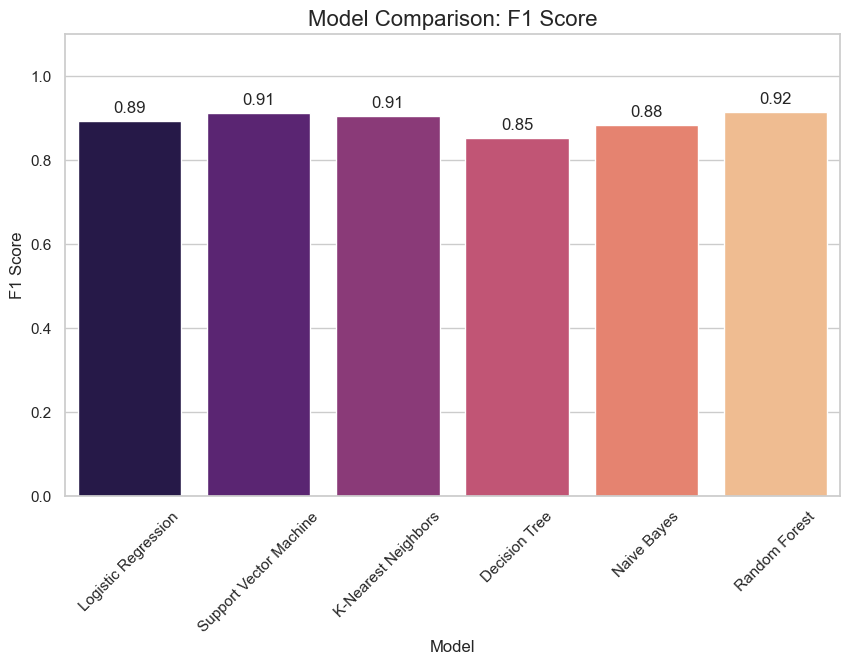

In [4]:
plt.figure(figsize=(10, 6))
plot = sns.barplot(x='Model', y='F1 Score', data=results_df, palette='magma')

plt.title('Model Comparison: F1 Score', fontsize=16)
plt.xticks(rotation=45)
plt.ylim(0, 1.1)

for p in plot.patches:
    plot.annotate(format(p.get_height(), '.2f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 9), 
                   textcoords = 'offset points')

plt.show()

C:\Users\spars\AppData\Local\Temp\ipykernel_26132\1519338601.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.barplot(x='Model', y='Precision', data=results_df, palette='rocket')


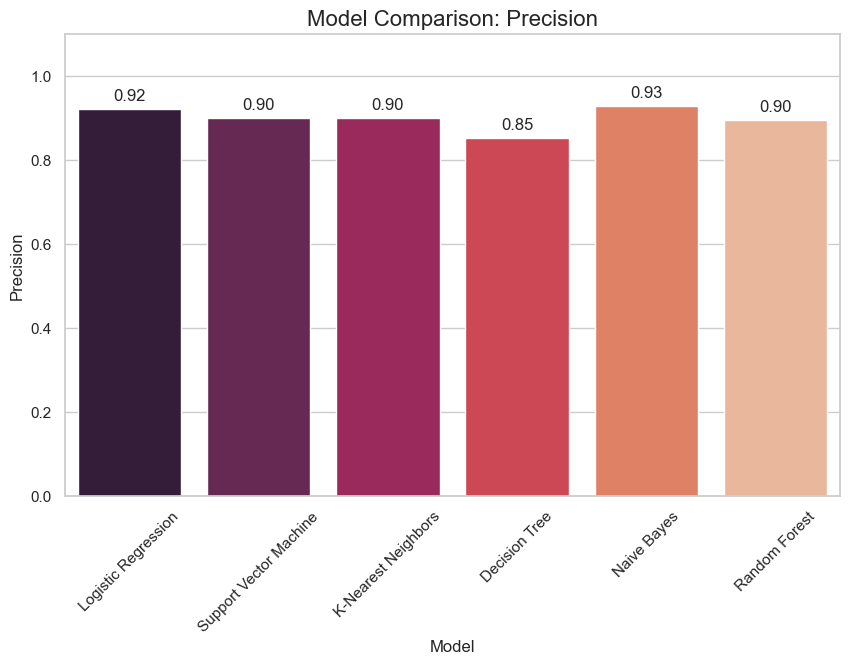

In [5]:
plt.figure(figsize=(10, 6))
plot = sns.barplot(x='Model', y='Precision', data=results_df, palette='rocket')

plt.title('Model Comparison: Precision', fontsize=16)
plt.xticks(rotation=45)
plt.ylim(0, 1.1)

for p in plot.patches:
    plot.annotate(format(p.get_height(), '.2f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 9), 
                   textcoords = 'offset points')

plt.show()

C:\Users\spars\AppData\Local\Temp\ipykernel_26132\3679257442.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.barplot(x='Model', y='Recall', data=results_df, palette='mako')


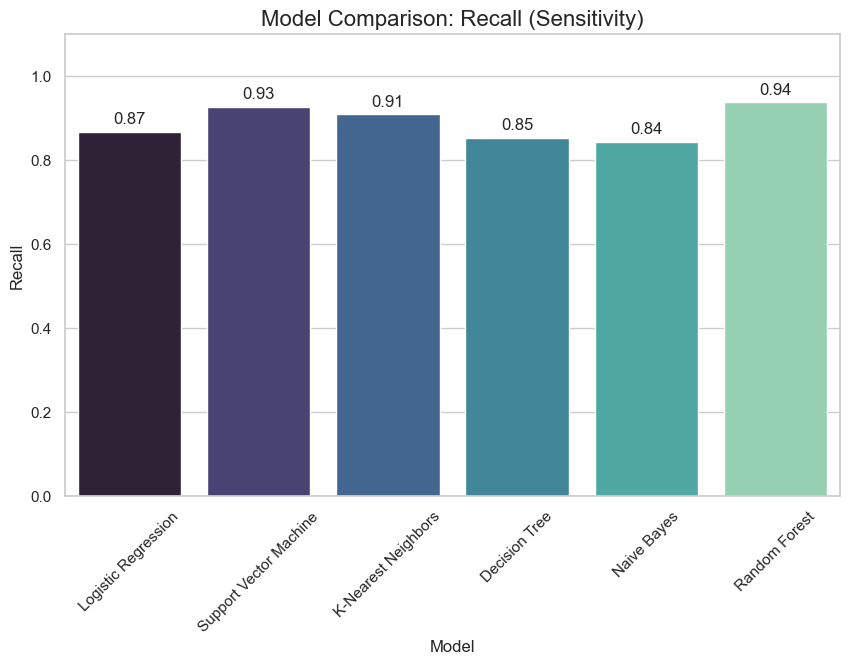

In [6]:
plt.figure(figsize=(10, 6))
plot = sns.barplot(x='Model', y='Recall', data=results_df, palette='mako')

plt.title('Model Comparison: Recall (Sensitivity)', fontsize=16)
plt.xticks(rotation=45)
plt.ylim(0, 1.1)

for p in plot.patches:
    plot.annotate(format(p.get_height(), '.2f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 9), 
                   textcoords = 'offset points')

plt.show()

C:\Users\spars\AppData\Local\Temp\ipykernel_26132\3713801614.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.barplot(x='Model', y='Specificity', data=results_df, palette='coolwarm')


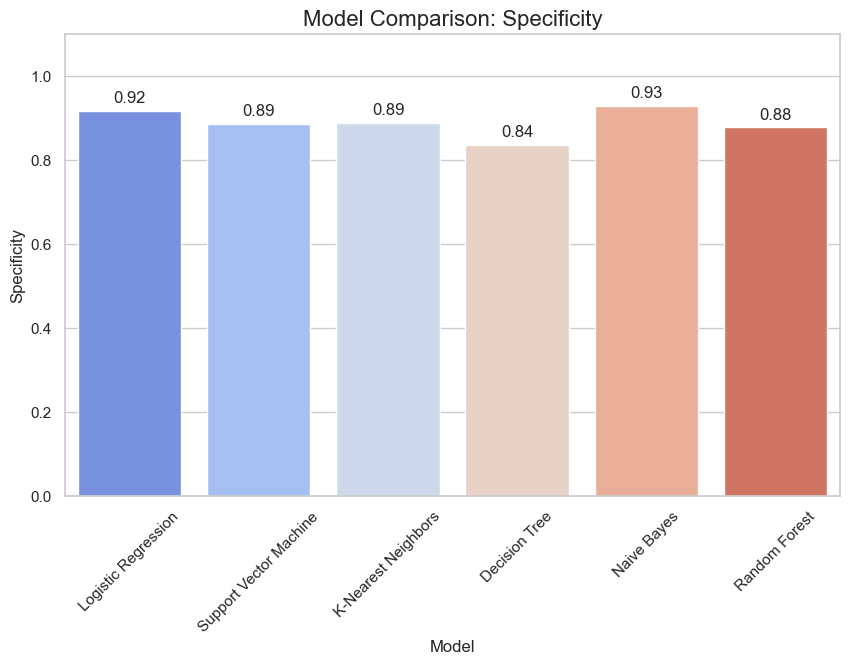

In [7]:
plt.figure(figsize=(10, 6))
plot = sns.barplot(x='Model', y='Specificity', data=results_df, palette='coolwarm')

plt.title('Model Comparison: Specificity', fontsize=16)
plt.xticks(rotation=45)
plt.ylim(0, 1.1)

for p in plot.patches:
    plot.annotate(format(p.get_height(), '.2f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 9), 
                   textcoords = 'offset points')

plt.show()